# Рекомендательная система фильмов

## Исследование данных и простые методы рекомендаций

**Цель:** по истории оценок предложить пользователю фильмы, которые могут ему понравиться. Используем MovieTweetings 200K: оценки пользователей, названия фильмов и жанры.

В ноутбуке идут понятные шаги: загрузка → EDA → разделение данных → популярность → рекомендации по похожим пользователям и фильмам → контентные рекомендации → проверка качества → сохранение модели для приложения.


In [1]:
# 0. Библиотеки и пути
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "ratings.dat").exists():
    PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
print("Папка проекта:", PROJECT_ROOT)


Папка проекта: C:\Users\Honor\Documents\Codex\2026-10-27\mysql-workbeanch-eda-2\outputs\movie_recommendation_system


## 1. Загрузка данных

Файл с оценками содержит пользователя, фильм, оценку от 0 до 10 и время. Файл с фильмами содержит ID, название и жанры. ID фильма читаем как текст, чтобы не потерять ведущие нули.


In [2]:
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat", sep=r"::", engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"],
    dtype={"user_id": "int32", "movie_id": "string", "rating": "float32", "timestamp": "int64"}
)
movies = pd.read_csv(
    DATA_DIR / "movies.dat", sep=r"::", engine="python", encoding="latin-1",
    names=["movie_id", "title", "genres"], dtype={"movie_id": "string"}
)
movies["release_year"] = pd.to_numeric(movies.title.str.extract(r"\((\d{4})\)")[0], errors="coerce")
ratings.head()


,user_id,movie_id,rating,timestamp
0,1,0068646,10.0,1381620027
1,1,0113277,10.0,1379466669
2,2,0790636,7.0,1389963947
3,2,0816711,8.0,1379963769
4,2,1091191,7.0,1391173869


## 2. EDA — знакомство с данными

Сначала проверим объём таблиц, пропуски, повторы и диапазон оценок. Это помогает заметить ошибки до построения моделей.


In [3]:
summary = pd.DataFrame({
    "Показатель": ["Оценки", "Пользователи", "Фильмы в оценках", "Фильмы в каталоге", "Пропуски в оценках", "Повторные пары пользователь-фильм"],
    "Значение": [len(ratings), ratings.user_id.nunique(), ratings.movie_id.nunique(), len(movies), int(ratings.isna().sum().sum()), int(ratings.duplicated(["user_id", "movie_id"]).sum())]
})
display(summary)
print("Диапазон рейтингов:", ratings.rating.min(), "—", ratings.rating.max())


,Показатель,Значение
0,Оценки,200000
1,Пользователи,25011
2,Фильмы в оценках,14732
3,Фильмы в каталоге,14732
4,Пропуски в оценках,0
5,Повторные пары пользователь-фильм,0


Диапазон рейтингов: 0.0 — 10.0


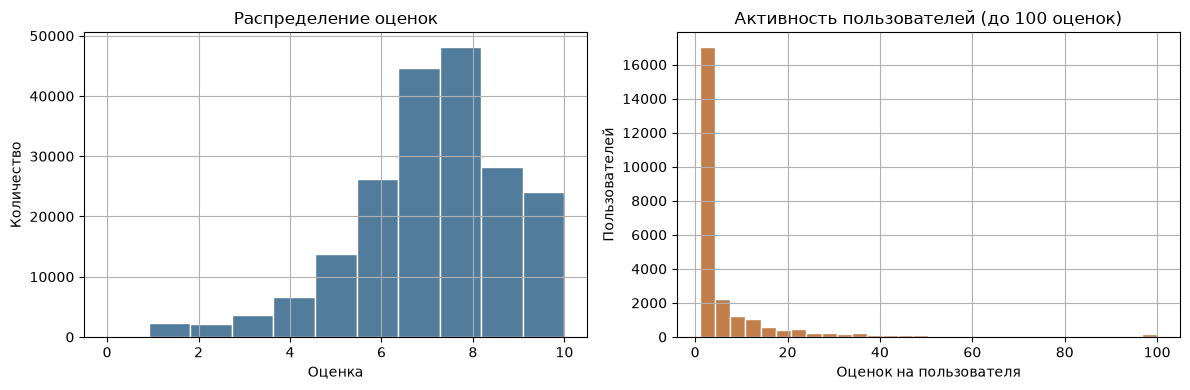

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings.rating.hist(bins=11, ax=axes[0], color="#527c9b", edgecolor="white")
axes[0].set(title="Распределение оценок", xlabel="Оценка", ylabel="Количество")
ratings.user_id.value_counts().clip(upper=100).hist(bins=30, ax=axes[1], color="#c17d4a", edgecolor="white")
axes[1].set(title="Активность пользователей (до 100 оценок)", xlabel="Оценок на пользователя", ylabel="Пользователей")
plt.tight_layout()


In [5]:
# Самые часто оцениваемые фильмы
ratings.groupby("movie_id").size().sort_values(ascending=False).head(10).rename("Число оценок").to_frame().merge(
    movies.set_index("movie_id")["title"], left_index=True, right_index=True
).reset_index()[["title", "Число оценок"]]


,title,Число оценок
0,Man of Steel (2013),2336
1,Gravity (2013),2295
2,Iron Man 3 (2013),2106
3,World War Z (2013),2076
4,Now You See Me (2013),1988
5,Star Trek Into Darkness (2013),1722
6,Oblivion (2013),1563
7,The Wolf of Wall Street (2013),1551
8,The Great Gatsby (2013),1494
9,Captain Phillips (2013),1452


## 3. Простое разделение на обучение и проверку

С помощью `train_test_split` случайно оставляем 20% оценок для проверки. Фиксируем `random_state=42`, чтобы при повторном запуске получили то же разделение. Для честной проверки оставляем в тесте только тех пользователей и фильмы, которые встречались в обучении.


In [6]:
train, test = train_test_split(ratings, test_size=0.2, random_state=RANDOM_STATE)
known_users = set(train.user_id)
known_movies = set(train.movie_id)
test = test.loc[test.user_id.isin(known_users) & test.movie_id.isin(known_movies)].copy()
print(f"Обучение: {len(train):,} оценок")
print(f"Проверка знакомых пользователей и фильмов: {len(test):,} оценок")


Обучение: 160,000 оценок
Проверка знакомых пользователей и фильмов: 36,122 оценок


## 4. Базовый метод: популярные фильмы

Считаем среднюю оценку фильма и число оценок. Затем используем сглаженный рейтинг: фильм с одной случайной высокой оценкой не должен сразу стать популярнее фильма с большой устойчивой историей. Это наш простой ориентир для сравнения.


In [7]:
global_mean = float(train.rating.mean())
popularity = train.groupby("movie_id").rating.agg(mean_rating="mean", rating_count="size").reset_index()
minimum_votes = max(10, float(popularity.rating_count.quantile(0.90)))
popularity["bayesian_score"] = (
    popularity.rating_count * popularity.mean_rating + minimum_votes * global_mean
) / (popularity.rating_count + minimum_votes)
popularity = popularity.sort_values(["bayesian_score", "rating_count"], ascending=False)
display(popularity.head(10).merge(movies, on="movie_id")[["title", "genres", "rating_count", "mean_rating", "bayesian_score"]])


,title,genres,rating_count,mean_rating,bayesian_score
0,The Shawshank Redemption (1994),Crime|Drama,273,9.531136,9.394332
1,The Dark Knight (2008),Action|Crime|Drama|Thriller,185,9.329730,9.151481
2,The Godfather (1972),Crime|Drama,137,9.262774,9.037101
3,The Lord of the Rings: The Return of the King ...,Action|Adventure|Fantasy,86,9.337210,8.987987
4,The Godfather: Part II (1974),Crime|Drama,75,9.386666,8.986566
5,Schindler's List (1993),Biography|Drama|History|War,106,9.150944,8.885086
6,The Green Mile (1999),Crime|Drama|Fantasy|Mystery,77,9.220779,8.860533
7,Inception (2010),Action|Adventure|Mystery|Sci-Fi|Thriller,220,8.945455,8.822482
8,Forrest Gump (1994),Drama|Romance,144,9.006945,8.819449
9,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,69,9.202899,8.813226


## 5. Коллаборативная фильтрация простыми словами

Идея: если два пользователя оценивали фильмы похоже, фильмы, понравившиеся одному, можно предложить другому. Для этого библиотека `NearestNeighbors` находит ближайших соседей по косинусному сходству. Та же идея применяется к фильмам: ищем похожие по оценкам.

Оценки храним в разреженной матрице: строки — пользователи, столбцы — фильмы. Большинство ячеек пустые, поэтому хранить только известные оценки экономнее.


In [8]:
def make_matrix(frame):
    user_ids = sorted(frame.user_id.unique())
    movie_ids = sorted(frame.movie_id.astype(str).unique())
    user_to_idx = {value: i for i, value in enumerate(user_ids)}
    movie_to_idx = {value: i for i, value in enumerate(movie_ids)}
    rows = frame.user_id.map(user_to_idx).to_numpy()
    cols = frame.movie_id.astype(str).map(movie_to_idx).to_numpy()
    matrix = csr_matrix((frame.rating.to_numpy(np.float32), (rows, cols)), shape=(len(user_ids), len(movie_ids)))
    return matrix, user_ids, movie_ids, user_to_idx, movie_to_idx

R_train, user_ids, movie_ids, user_to_idx, movie_to_idx = make_matrix(train)
counts = np.diff(R_train.indptr)
user_mean = np.divide(np.asarray(R_train.sum(axis=1)).ravel(), counts, out=np.zeros(len(user_ids), dtype=np.float32), where=counts > 0)
R_centered = R_train.copy()
R_centered.data -= np.repeat(user_mean, counts)
presence = R_train.copy()
presence.data[:] = 1
print("Матрица:", R_train.shape, "| заполнено оценками:", R_train.nnz)


Матрица: (22753, 13297) | заполнено оценками: 160000


In [9]:
def nearest_similarity(matrix, neighbors=20):
    """Возвращает сходства с ближайшими строками матрицы."""
    n = matrix.shape[0]
    k = min(neighbors, max(1, n - 1))
    model = NearestNeighbors(n_neighbors=k, metric="cosine", algorithm="brute")
    model.fit(matrix)
    distances, indices = model.kneighbors()
    rows, cols, values = [], [], []
    for i, (row_indices, row_distances) in enumerate(zip(indices, distances)):
        for j, distance in zip(row_indices, row_distances):
            similarity = 1.0 - float(distance)
            if i != j and similarity > 0:
                rows.append(i); cols.append(j); values.append(similarity)
    return csr_matrix((values, (rows, cols)), shape=(n, n), dtype=np.float32)

user_similarity = nearest_similarity(R_centered, neighbors=20)
item_similarity = nearest_similarity(R_centered.T.tocsr(), neighbors=20)
print("Похожие пользователи и фильмы найдены.")


Похожие пользователи и фильмы найдены.


## 6. Сходство по названию и жанрам

Коллаборативный метод использует историю оценок. Контентный метод сравнивает сами фильмы. Преобразуем названия и жанры в TF-IDF признаки: общие информативные слова получают больший вес.


In [10]:
catalog = movies.drop_duplicates("movie_id").copy().reset_index(drop=True)
catalog["movie_id"] = catalog.movie_id.astype(str)
content_text = (catalog.genres.fillna("").str.replace("|", " ", regex=False) + " " + catalog.title.fillna("")).str.strip()
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)
content_matrix = vectorizer.fit_transform(content_text)
content_to_idx = {movie_id: i for i, movie_id in enumerate(catalog.movie_id)}
print("Фильмов:", content_matrix.shape[0], "| текстовых признаков:", content_matrix.shape[1])


Фильмов: 14732 | текстовых признаков: 8922


## 7. Проверка качества рекомендаций

Сравним популярность, рекомендации по похожим пользователям и их простой гибрид. Релевантным считаем фильм с оценкой не ниже 7. Для списка из десяти фильмов считаем Precision@10, Recall@10, NDCG@10 и HitRate@10.


In [11]:
def percentile_scores(values):
    values = pd.Series(values, dtype=float)
    return values.rank(method="average", pct=True).to_numpy()

def rank_metrics(recommended, relevant, k=10):
    top = recommended[:k]
    hits = np.array([item in relevant for item in top], dtype=float)
    precision = hits.sum() / k
    recall = hits.sum() / max(1, len(relevant))
    dcg = sum(hit / np.log2(i + 2) for i, hit in enumerate(hits))
    ideal = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return precision, recall, dcg / ideal if ideal else 0.0, float(hits.sum() > 0)

# Для каждого пользователя тестируем один и тот же набор кандидатов.
available_users = test.loc[test.rating >= 7, "user_id"].drop_duplicates()
test_users = available_users.sample(n=min(100, len(available_users)), random_state=RANDOM_STATE).tolist()
movie_means = train.groupby("movie_id").rating.mean().to_dict()
movie_pop = dict(zip(popularity.movie_id, popularity.bayesian_score))


In [12]:
def user_cf_scores(user_id):
    if user_id not in user_to_idx:
        return {}
    u = user_to_idx[user_id]
    sim = user_similarity.getrow(u)
    if sim.nnz == 0:
        return {}
    weights = csr_matrix((sim.data, (np.zeros(sim.nnz), sim.indices)), shape=(1, len(user_ids)))
    numerator = (weights @ R_centered).toarray().ravel()
    denominator = (weights @ presence).toarray().ravel()
    valid = denominator > 0
    scores = np.full(len(movie_ids), np.nan)
    scores[valid] = user_mean[u] + numerator[valid] / denominator[valid]
    return {movie_ids[i]: float(scores[i]) for i in range(len(movie_ids)) if np.isfinite(scores[i])}

def content_user_scores(user_id, profile):
    liked = profile.loc[(profile.user_id == user_id) & (profile.rating >= 7)]
    liked = liked[liked.movie_id.isin(content_to_idx)]
    if liked.empty:
        return {}
    idx = liked.movie_id.map(content_to_idx).to_numpy()
    weights = np.maximum(liked.rating.to_numpy(float) - 6, 1)
    vector = content_matrix[idx].multiply(weights[:, None]).sum(axis=0)
    scores = np.asarray(content_matrix @ np.asarray(vector).ravel()).ravel()
    return dict(zip(catalog.movie_id, scores))


In [13]:
def recommend_for_user(user_id, method="hybrid", limit=10):
    profile = train.loc[train.user_id == user_id]
    seen = set(profile.movie_id.astype(str))
    candidates = [m for m in movie_ids if m not in seen]
    cf = user_cf_scores(user_id)
    content = content_user_scores(user_id, profile)
    if method == "collaborative":
        scores = {m: cf[m] for m in candidates if m in cf}
    elif method == "popularity":
        scores = {m: movie_pop.get(m, 0) for m in candidates}
    else:
        methods = {"collaborative": cf, "popularity": movie_pop, "content": content}
        weights = {"collaborative": 0.60, "popularity": 0.25, "content": 0.15}
        # Сначала переводим оценки каждого метода в ранги от 0 до 1,
        # как это делает API. Так шкалы CF, популярности и TF-IDF сопоставимы.
        ranks = {}
        for name, values in methods.items():
            available_values = {key: values[key] for key in candidates if key in values}
            ranks[name] = pd.Series(available_values, dtype=float).rank(pct=True).to_dict()
        scores = {}
        for key in candidates:
            available = [(weights[name], ranks[name][key]) for name in methods if key in ranks[name]]
            total = sum(weight for weight, _ in available)
            scores[key] = sum(weight * value for weight, value in available) / total if total else 0.0
    return sorted(scores, key=scores.get, reverse=True)[:limit]

results = {"Популярность": [], "Похожие пользователи": [], "Гибрид": []}
for uid in test_users:
    relevant = set(test.loc[(test.user_id == uid) & (test.rating >= 7), "movie_id"].astype(str))
    seen = set(train.loc[train.user_id == uid, "movie_id"].astype(str))
    candidates = [m for m in movie_ids if m not in seen]
    pop_order = sorted(candidates, key=lambda m: movie_pop.get(m, 0), reverse=True)[:10]
    for name, recs in [("Популярность", pop_order), ("Похожие пользователи", recommend_for_user(uid, "collaborative")), ("Гибрид", recommend_for_user(uid, "hybrid"))]:
        results[name].append(rank_metrics(recs, relevant))
rows = []
for name, values in results.items():
    avg = np.mean(values, axis=0)
    rows.append({"Метод": name, "Precision@10": avg[0], "Recall@10": avg[1], "NDCG@10": avg[2], "HitRate@10": avg[3]})
metrics = pd.DataFrame(rows).sort_values("NDCG@10", ascending=False)
display(metrics.round(4))


,Метод,Precision@10,Recall@10,NDCG@10,HitRate@10
2,Гибрид,0.013,0.0355,0.0338,0.12
1,Похожие пользователи,0.007,0.0256,0.0114,0.07
0,Популярность,0.003,0.0158,0.0069,0.03


## 8. Обучение для приложения и сохранение

После проверки строим те же простые матрицы на всех доступных оценках и сохраняем их вместе с каталогом и TF-IDF признаками. API загружает этот файл и рассчитывает рекомендации без повторного обучения.


In [14]:
R_all, all_user_ids, all_movie_ids, all_user_to_idx, all_movie_to_idx = make_matrix(ratings)
all_counts = np.diff(R_all.indptr)
all_user_mean = np.divide(np.asarray(R_all.sum(axis=1)).ravel(), all_counts, out=np.zeros(len(all_user_ids), dtype=np.float32), where=all_counts > 0)
R_all_centered = R_all.copy()
R_all_centered.data -= np.repeat(all_user_mean, all_counts)
all_presence = R_all.copy(); all_presence.data[:] = 1
all_user_similarity = nearest_similarity(R_all_centered, neighbors=20)
all_item_similarity = nearest_similarity(R_all_centered.T.tocsr(), neighbors=20)


In [15]:
all_pop = ratings.groupby("movie_id").rating.agg(mean_rating="mean", rating_count="size").reset_index()
all_prior = float(ratings.rating.mean())
all_m = max(10, float(all_pop.rating_count.quantile(0.90)))
all_pop["bayesian_score"] = (all_pop.rating_count * all_pop.mean_rating + all_m * all_prior) / (all_pop.rating_count + all_m)
all_pop = all_pop.merge(catalog, on="movie_id", how="right")
all_pop["bayesian_score"] = all_pop.bayesian_score.fillna(all_prior)

bundle = {
    "ratings": R_all, "centered_ratings": R_all_centered, "rating_presence": all_presence,
    "user_mean": all_user_mean, "user_similarity": all_user_similarity, "item_similarity": all_item_similarity,
    "model_user_ids": all_user_ids, "model_movie_ids": all_movie_ids,
    "user_to_idx": all_user_to_idx, "movie_to_idx": all_movie_to_idx,
    "user_neighbors": 20, "item_neighbors": 20, "movies": catalog,
    "content_matrix": content_matrix, "content_to_idx": content_to_idx, "content_movie_ids": catalog.movie_id.tolist(),
    "relevance_threshold": 7, "popularity": all_pop,
    "hybrid_weights": {"collaborative": 0.60, "popularity": 0.25, "content": 0.15},
}
model_path = MODEL_DIR / "recommender_bundle.joblib"
joblib.dump(bundle, model_path)
print("Модель сохранена:", model_path)
print(f"В комплекте: {len(all_user_ids):,} пользователей, {len(all_movie_ids):,} фильмов.")


Модель сохранена: C:\Users\Honor\Documents\Codex\2026-10-27\mysql-workbeanch-eda-2\outputs\movie_recommendation_system\models\recommender_bundle.joblib
В комплекте: 25,011 пользователей, 14,732 фильмов.


## 9. Выводы и ограничения

Мы изучили оценки, построили базовый рейтинг популярности, рекомендации по похожим пользователям и фильмам и контентные рекомендации по жанрам и названию. Гибрид объединяет эти сигналы. Качество сравнили на отложенной части данных метриками для верхних 10 рекомендаций.

Ограничения: оценок мало относительно всех возможных пар пользователь-фильм; случайное разбиение проверяет знакомых пользователей и фильмы; у новых пользователей мало или нет истории; в каталоге доступны только название и жанры. Полученные метрики относятся к этой выборке и не гарантируют такие же результаты для всех зрителей.
